In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. LOADING THE DATASET LOCALLY (fail to fetch directly from "KAGGLEHub" need api key)

file_path = "../data/digital_marketing_campaign_dataset.csv" 

# Load the file into a Pandas DataFrame
df = pd.read_csv(file_path)

print("\nFirst 5 records successfully loaded:")
print(df.head())

# Drop the CustomerID column: it holds no predictive value. 
if 'CustomerID' in df.columns:
    df = df.drop('CustomerID', axis=1)

#Verification
# print(df.columns) #we are starting with 'age' now
# print(df.shape) #19 intead of 20 columns now



First 5 records successfully loaded:
   CustomerID  Age  Gender  Income CampaignChannel CampaignType      AdSpend  \
0        8000   56  Female  136912    Social Media    Awareness  6497.870068   
1        8001   69    Male   41760           Email    Retention  3898.668606   
2        8002   46  Female   88456             PPC    Awareness  1546.429596   
3        8003   32  Female   44085             PPC   Conversion   539.525936   
4        8004   60  Female   83964             PPC   Conversion  1678.043573   

   ClickThroughRate  ConversionRate  WebsiteVisits  PagesPerVisit  TimeOnSite  \
0          0.043919        0.088031              0       2.399017    7.396803   
1          0.155725        0.182725             42       2.917138    5.352549   
2          0.277490        0.076423              2       8.223619   13.794901   
3          0.137611        0.088004             47       4.540939   14.688363   
4          0.252851        0.109940              0       2.046847   13.99337

In [ ]:
#2. STRUCTURAL AUDIT
print("\n--- Data Schema & Missing Values ---")
df.info() # checks data types and any missing values. object = string = need processing


print("\n--- Missing Value Count ---")
print(df.isnull().sum()) # perfect 0 null values # This also counts blank spaces

# 3. STATISTICAL SUMMARY
print("\n--- Statistical Summary ---")
# .describe() gives us the mean, min, max, and percentiles for numerical columns. Gives easy outlier detection.
print(df.describe()) #NB mean for Conversion 0.8765 (the model couldbe biased towards predicting 1 as it would result in a 87% accuracy score)


--- Data Schema & Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  8000 non-null   int64  
 1   Gender               8000 non-null   object 
 2   Income               8000 non-null   int64  
 3   CampaignChannel      8000 non-null   object 
 4   CampaignType         8000 non-null   object 
 5   AdSpend              8000 non-null   float64
 6   ClickThroughRate     8000 non-null   float64
 7   ConversionRate       8000 non-null   float64
 8   WebsiteVisits        8000 non-null   int64  
 9   PagesPerVisit        8000 non-null   float64
 10  TimeOnSite           8000 non-null   float64
 11  SocialShares         8000 non-null   int64  
 12  EmailOpens           8000 non-null   int64  
 13  EmailClicks          8000 non-null   int64  
 14  PreviousPurchases    8000 non-null   int64  
 15  

/var/folders/s5/bl8l56xd7cg_5l8jz474tpd00000gn/T/ipykernel_38410/2775743856.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Conversion', palette='viridis')


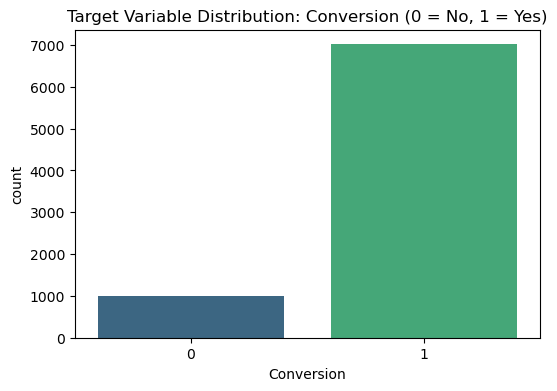

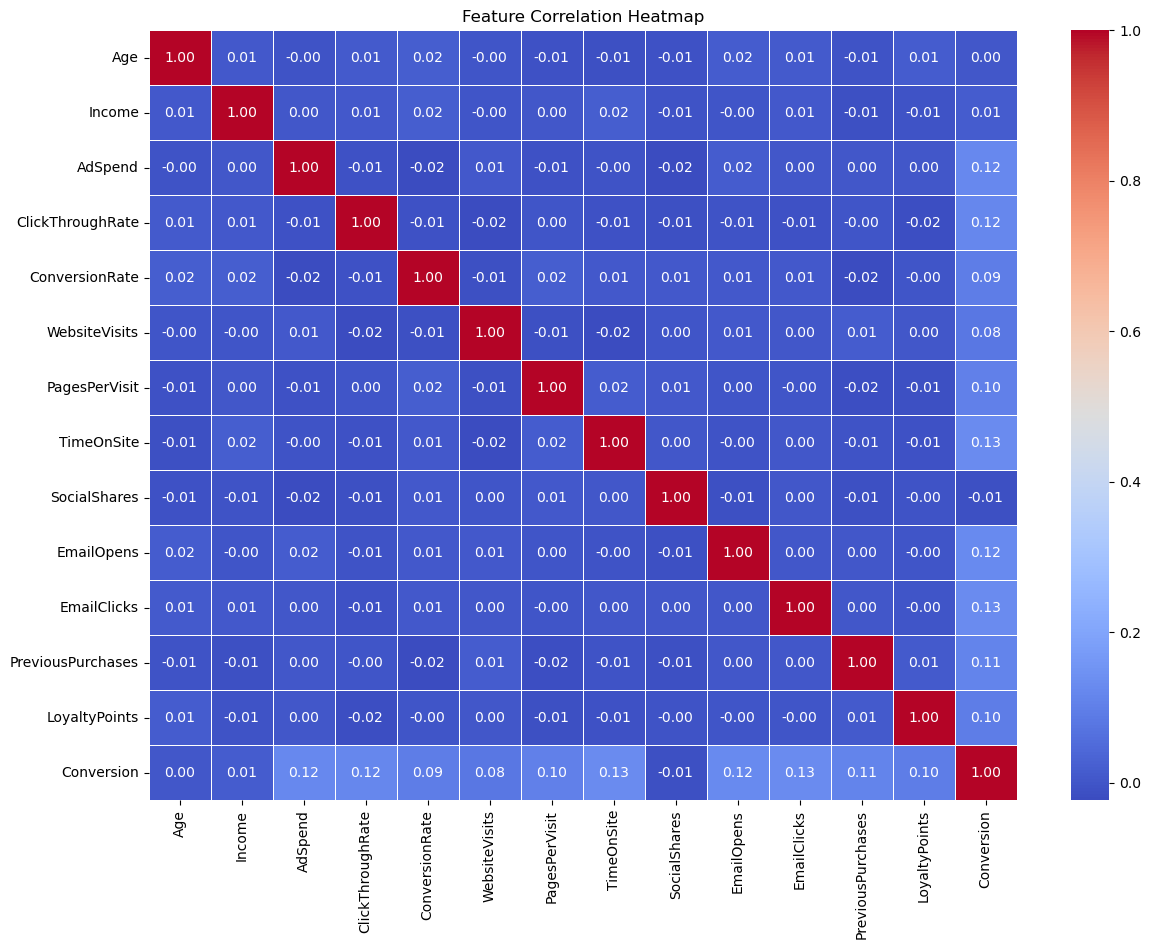


EDA Complete! Look at the Heatmap: Which feature has the highest number (closest to 1.0) correlating with 'Conversion'?


In [ ]:
#4. VISUALIZING RELATIONSHIPS

# Let's visually see our Target Variable distribution (or unevenness honestly). 
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Conversion', palette='viridis')
plt.title('Target Variable Distribution: Conversion (0 = No, 1 = Yes)')
plt.show()

# the Correlation Heatmap
# We isolate only the numerical columns for this math matrix.
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(14, 10))
# .corr() calculates the Pearson correlation coefficient between -1 (opposite) and 1 (perfectly matched).
# 'annot=True' prints the actual decimal numbers inside the colored boxes.
sns.heatmap(df[numerical_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

print("\nEDA Complete! Looking at the Heatmap no clear winner/driver here: TimeOnSite (0.13), EmailClicks (0.13) et AdSpend (0.12). offers a weak correlation with 'Conversion'? Plus the variables are independent (No multicollinearity)")

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# 'y' the prediction (Conversion)
y = df['Conversion']
# 'X' the features
X = df.drop('Conversion', axis=1)

# creates binary (0/1) out of object/string columns for every category inside it.
X_encoded = pd.get_dummies(X, drop_first=True) # 'drop_first=True' prevent perfectly correlated duplicate columns

print(f"Shape of our data after encoding: {X_encoded.shape}")
print("Notice how the number of columns increased because of the new category columns!")

# We give 80% of the data to the AI to learn (Train), and hold back 20% for the final exam (Test)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print(f"\nTraining set size: {X_train.shape[0]} customers")
print(f"Testing set size: {X_test.shape[0]} customers")

# As seen last week: we scale the data so 'Income' (150,000) doesn't overpower 'ClickThroughRate' (0.2)
scaler = StandardScaler()

# We "fit" (calculate the math) ONLY on the training data, then transform it
X_train_scaled = scaler.fit_transform(X_train)

# We only "transform" the test data
X_test_scaled = scaler.transform(X_test)

print("\nData is successfully encoded, split, and scaled. We are ready for Machine Learning!")

Shape of our data after encoding: (8000, 21)
Notice how the number of columns increased because of the new category columns!

Training set size: 6400 customers
Testing set size: 1600 customers

Data is successfully encoded, split, and scaled. We are ready for Machine Learning!


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("\n--- 1. Training the Model ---")
# We choose Random Forest because it acts like a committee voting on the best prediction.
#As we saw in week 2 class activity Random Forests is the next step when it comes to classification problems over Logistic Regression and Decision Trees.
# random_state=42 ensures we get the exact same results every time we run the code.
rf_model = RandomForestClassifier(random_state=42) 
# .fit() is where the actual "learning" happens!
rf_model.fit(X_train_scaled, y_train)
print("Model training complete!")

# We ask the trained model to guess the answers for the 20% of data it has NEVER seen
y_pred = rf_model.predict(X_test_scaled)

print("\n--- 3. Evaluating Performance ---")
# We compare the model's guesses (y_pred) against the actual true answers (y_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"\n Random Forest Results:")
print(f"Accuracy:  {accuracy * 100:.2f}% (How many guesses were correct overall?)")
print(f"Precision: {precision * 100:.2f}% (When it predicted a purchase, how often was it right?)")
print(f"Recall:    {recall * 100:.2f}% (Out of all actual purchases, how many did it find?)")
print(f"F1 Score:  {f1 * 100:.2f}% (The balance between Precision and Recall)")


#lets compare the model's predictions with a classic Logistic Regression model
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

# We compare the model's guesses (y_pred) against the actual true answers (y_test)
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print(f"\n Logistic Regression Results:")
print(f"Accuracy:  {accuracy_lr * 100:.2f}%")
print(f"Precision: {precision_lr * 100:.2f}%")
print(f"Recall:    {recall_lr * 100:.2f}%")
print(f"F1 Score:  {f1_lr * 100:.2f}%")

#lets compare the model's predictions with a classic tree model
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)
y_pred_dt = dt_model.predict(X_test_scaled)

# We compare the model's guesses (y_pred) against the actual true answers (y_test)
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

print(f"\n Decision Tree Results:")
print(f"Accuracy:  {accuracy_dt * 100:.2f}%")
print(f"Precision: {precision_dt * 100:.2f}%")
print(f"Recall:    {recall_dt * 100:.2f}%")
print(f"F1 Score:  {f1_dt * 100:.2f}%")


print("\n--- 4. Summary of Model Performance ---")
print(f"Random Forest: Accuracy={accuracy * 100:.2f}%, Precision={precision * 100:.2f}%, Recall={recall * 100:.2f}%, F1 Score={f1 * 100:.2f}%")
print(f"Logistic Regression: Accuracy={accuracy_lr * 100:.2f}%, Precision={precision_lr * 100:.2f}%, Recall={recall_lr * 100:.2f}%, F1 Score={f1_lr * 100:.2f}%")
print(f"Decision Tree: Accuracy={accuracy_dt * 100:.2f}%, Precision={precision_dt * 100:.2f}%, Recall={recall_dt * 100:.2f}%, F1 Score={f1_dt * 100:.2f}%")
print("\nThe Random Forest model outperformed both Logistic Regression and Decision Tree models in terms of Accuracy, Precision, Recall, and F1 Score. This suggests that the Random Forest model is better suited for predicting customer conversion in this dataset.")
print("NB: 100 people who actually ended up buying something, Random Forest successfully found 99 of them which is an extremely high recall score of 0.99, indicating that the model is very effective at identifying actual purchasers.")
print("Decision Tree struggled the most, with its Accuracy dropping to 83.44%")




--- 1. Training the Model ---
Model training complete!

--- 2. Making Predictions ---

--- 3. Evaluating Performance ---

 Random Forest Results:
Accuracy:  89.31% (How many guesses were correct overall?)
Precision: 89.61% (When it predicted a purchase, how often was it right?)
Recall:    99.36% (Out of all actual purchases, how many did it find?)
F1 Score:  94.23% (The balance between Precision and Recall)

 Logistic Regression Results:
Accuracy:  88.75%
Precision: 89.70%
Recall:    98.51%
F1 Score:  93.90%

 Decision Tree Results:
Accuracy:  83.44%
Precision: 91.43%
Recall:    89.54%
F1 Score:  90.48%
